In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("/Users/ibrahim/code/ibrahimdata0/The Smart Room/Occupancy.csv")

# Display the first 5 rows
df.head()


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1


# Setup and a first look
defines the target, builds the list of sensor features, and adds a readable label column for plots. It then checks the shape, data types, missing values, and duplicates before any analysis.

In [13]:
sns.set_theme(style="whitegrid")

target = "Occupancy"

# Parse the timestamp so we can extract time-based patterns later
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"])

# All numeric columns except the target are sensor features
features = [c for c in df.select_dtypes(include="number").columns if c != target]

# Readable labels for plots
df["Status"] = df[target].map({0: "Not Occupied", 1: "Occupied"})

print("Shape:", df.shape)
print("Features:", features)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.info()

Shape: (20560, 8)
Features: ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']

Missing values:
 date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
Status           0
dtype: int64

Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           20560 non-null  datetime64[ns]
 1   Temperature    20560 non-null  float64       
 2   Humidity       20560 non-null  float64       
 3   Light          20560 non-null  float64       
 4   CO2            20560 non-null  float64       
 5   HumidityRatio  20560 non-null  float64       
 6   Occupancy      20560 non-null  int64         
 7   Status         20560 non-null  object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 1.3+ MB


# Descriptive statistics
This cell checks class balance. If one class dominates, accuracy alone will be misleading later, so you would also need precision, recall, and F1.

In [14]:
# Overall descriptive statistics
display(df[features].describe().T.round(2))

# Mean and median of each sensor per occupancy status
display(df.groupby("Status")[features].agg(["mean", "median"]).T.round(2))

,count,mean,std,min,25%,50%,75%,max
Temperature,20560.0,20.91,1.06,19.00,20.2,20.70,21.52,24.41
Humidity,20560.0,27.66,4.98,16.74,24.5,27.29,31.29,39.50
Light,20560.0,130.76,210.43,0.00,0.0,0.00,301.00,1697.25
CO2,20560.0,690.55,311.20,412.75,460.0,565.42,804.67,2076.50
HumidityRatio,20560.0,0.00,0.00,0.00,0.0,0.00,0.00,0.01


Status                Not Occupied  Occupied
Temperature   mean           20.58     21.98
              median         20.50     21.89
Humidity      mean           27.53     28.08
              median         27.15     27.88
Light         mean           25.24    481.97
              median          0.00    454.00
CO2           mean          605.00    975.32
              median        511.00    928.58
HumidityRatio mean            0.00      0.00
              median          0.00      0.00

# Distribution of occupancy states

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


,count,percent
Status,,
Not Occupied,15810,76.9
Occupied,4750,23.1


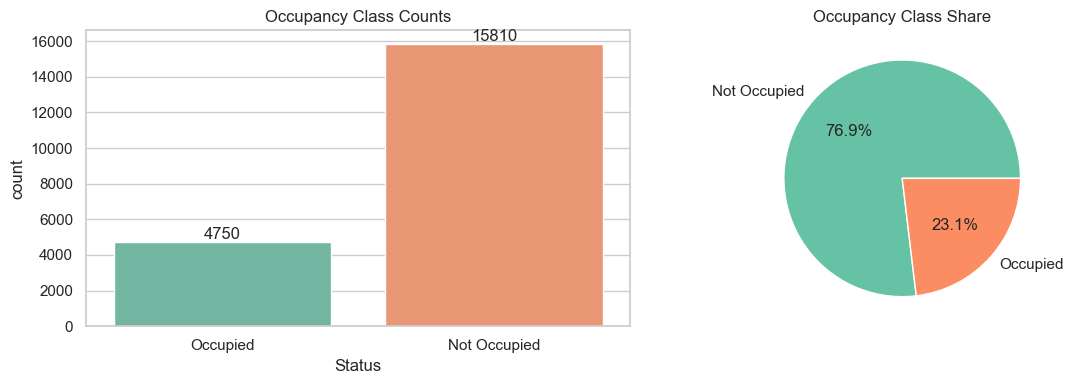

In [15]:
counts = df["Status"].value_counts()
pct = df["Status"].value_counts(normalize=True) * 100
display(pd.DataFrame({"count": counts, "percent": pct.round(2)}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Status", hue="Status", ax=axes[0], palette="Set2", legend=False)
axes[0].set_title("Occupancy Class Counts")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}",
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=sns.color_palette("Set2"))
axes[1].set_title("Occupancy Class Share")

plt.tight_layout()
plt.show()

# Compare sensor features by occupancy
The boxplots compare medians, spread, and outliers per class. The density plots show how much the two distributions overlap. Little overlap means the feature separates the classes well.

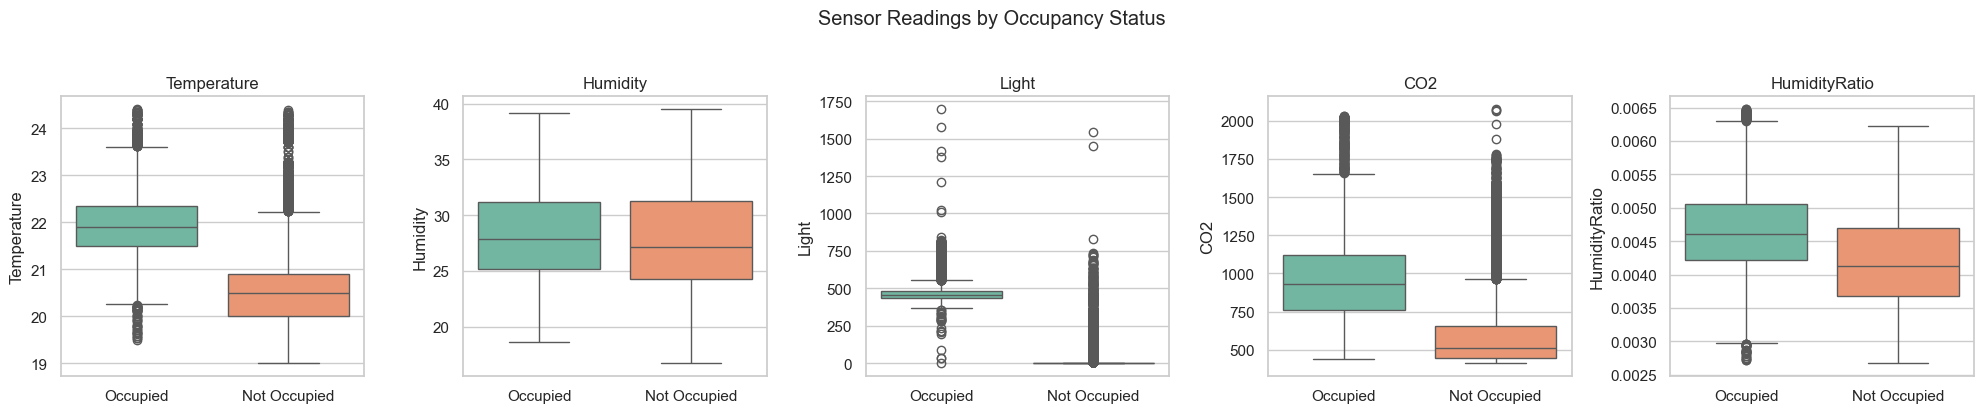

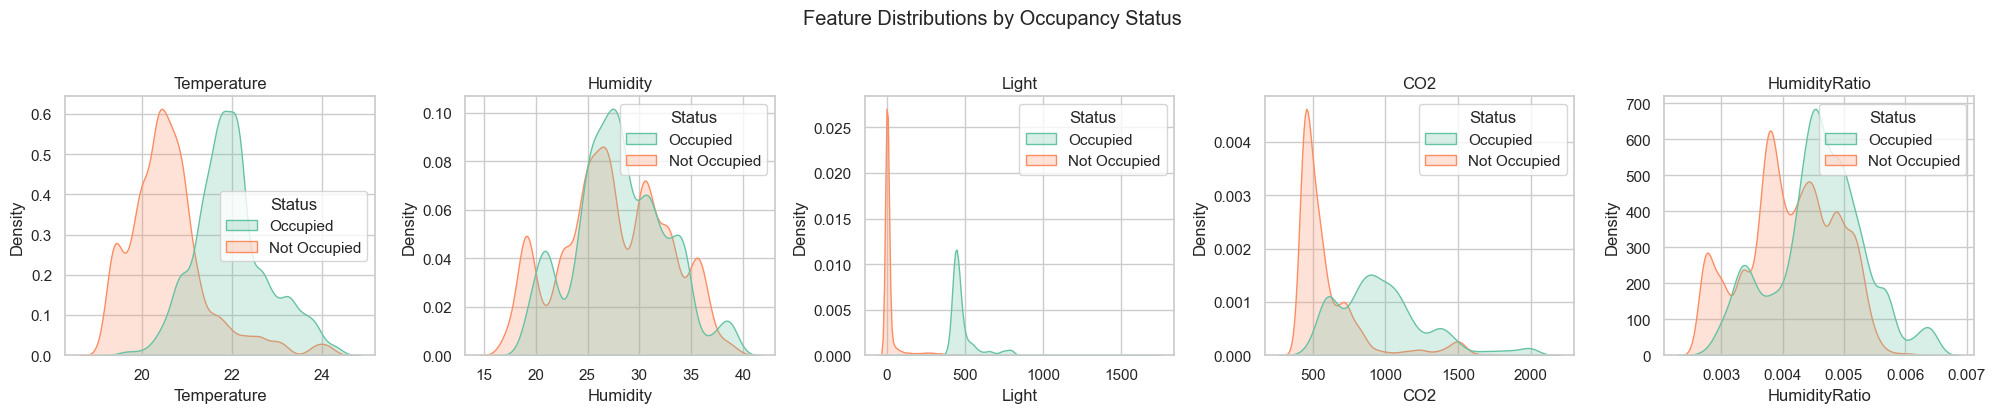

In [16]:
n = len(features)

# Boxplots
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x="Status", y=col, hue="Status", ax=ax, palette="Set2", legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Sensor Readings by Occupancy Status", y=1.03)
plt.tight_layout()
plt.show()

# Density plots
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
for ax, col in zip(axes, features):
    sns.kdeplot(data=df, x=col, hue="Status", fill=True, common_norm=False, ax=ax, palette="Set2")
    ax.set_title(col)
plt.suptitle("Feature Distributions by Occupancy Status", y=1.03)
plt.tight_layout()
plt.show()

# Correlations
This cell shows how each sensor relates to occupancy and to the other sensors. Strong correlations between features, such as Humidity and HumidityRatio, point to redundancy you may want to handle before modeling.

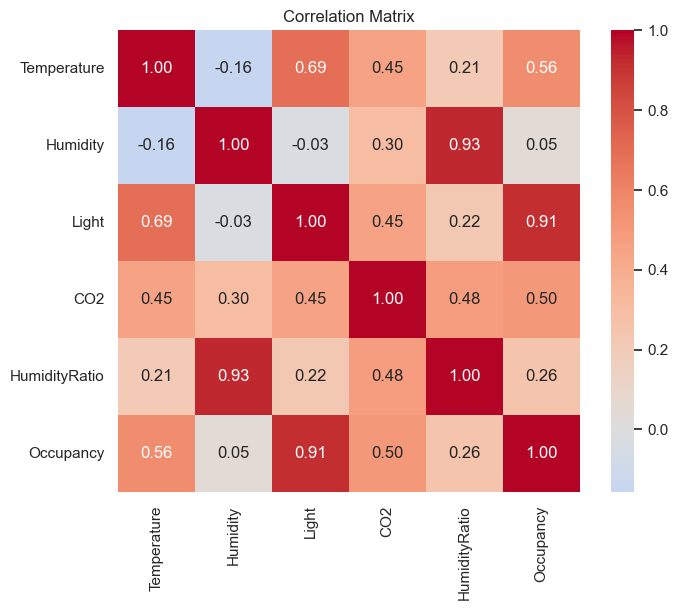

Light            0.915
Temperature      0.556
CO2              0.502
HumidityRatio    0.257
Humidity         0.046
Name: Occupancy, dtype: float64

In [17]:
corr = df[features + [target]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix")
plt.show()

# Correlation of each feature with the target, ranked
display(corr[target].drop(target).sort_values(ascending=False).round(3))

# Time patterns
Occupancy in an office follows human routines. This cell shows when the room tends to be occupied by hour and by weekday, and plots the sensors over time against the occupancy state.

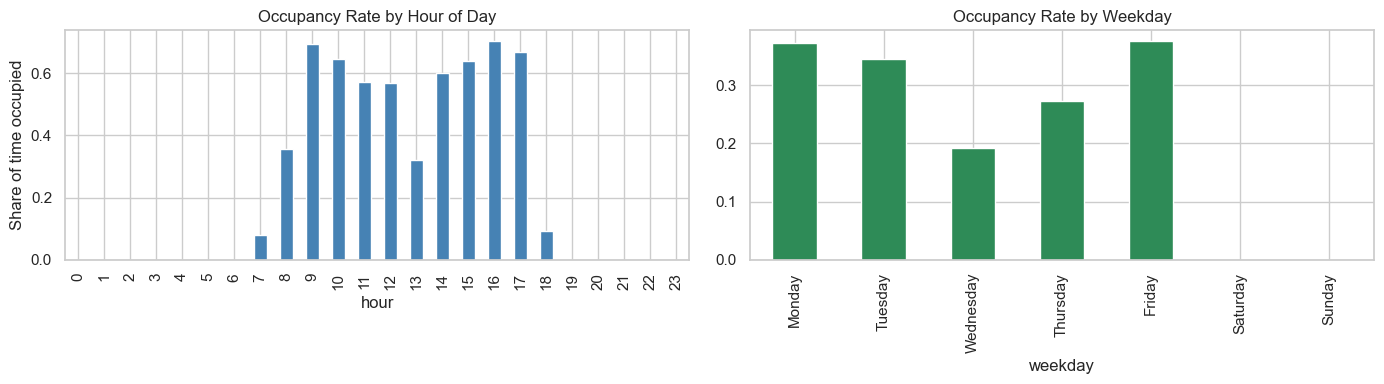

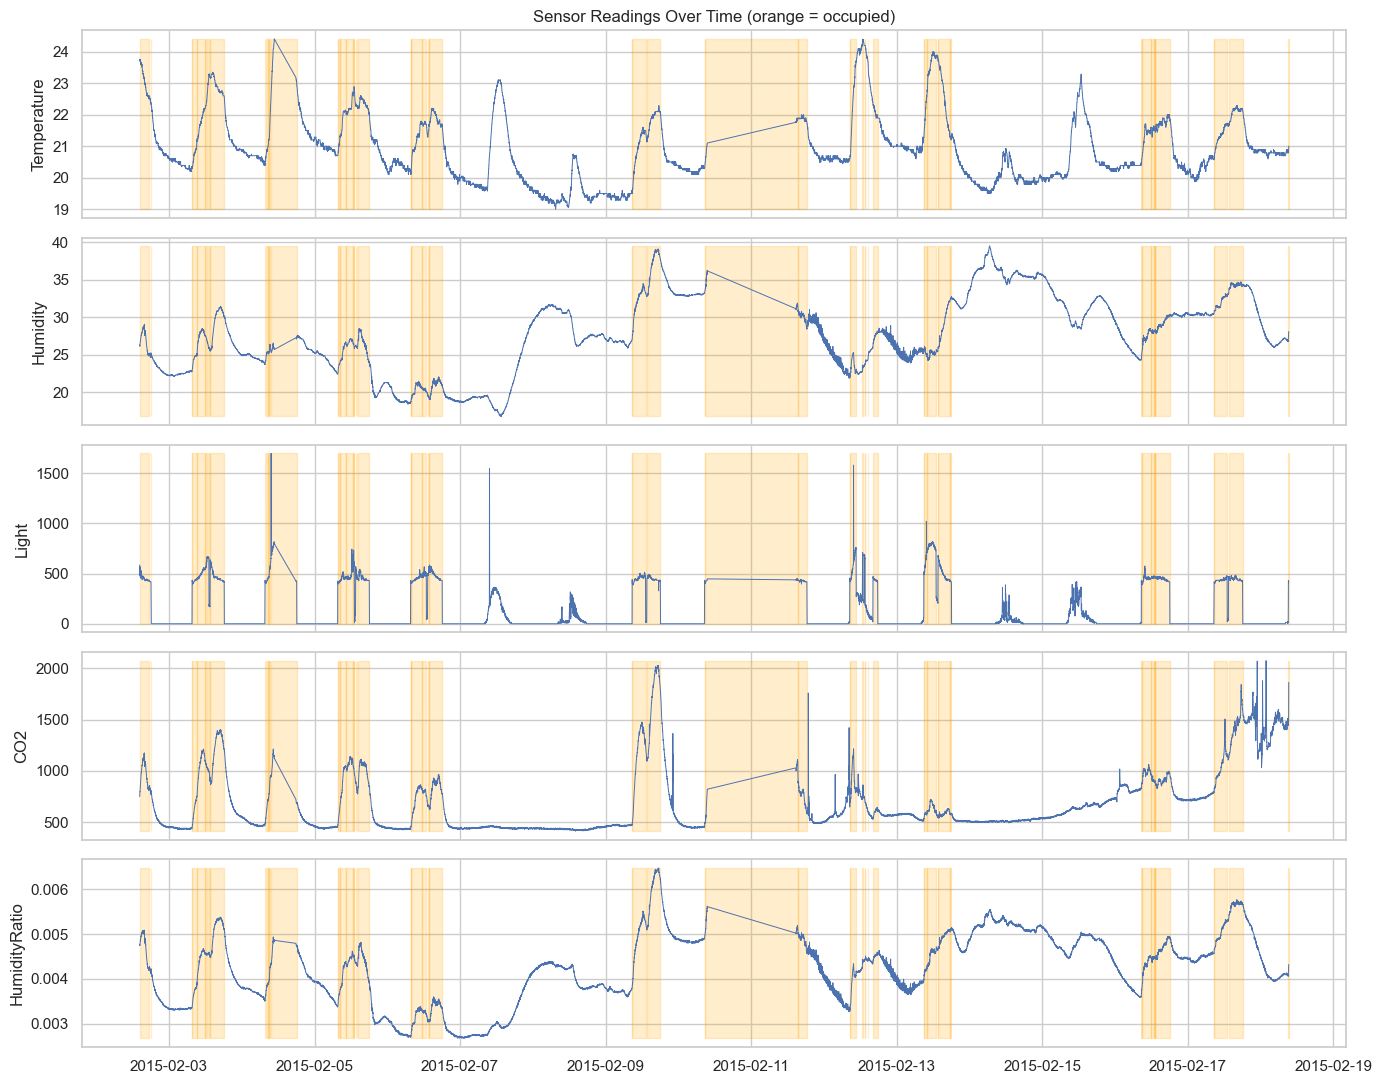

In [18]:
if "date" in df.columns:
    df["hour"] = df["date"].dt.hour
    df["weekday"] = df["date"].dt.day_name()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    df.groupby("hour")[target].mean().plot(kind="bar", ax=axes[0], color="steelblue")
    axes[0].set_title("Occupancy Rate by Hour of Day")
    axes[0].set_ylabel("Share of time occupied")

    order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    (df.groupby("weekday")[target].mean()
       .reindex([d for d in order if d in df["weekday"].unique()])
       .plot(kind="bar", ax=axes[1], color="seagreen"))
    axes[1].set_title("Occupancy Rate by Weekday")

    plt.tight_layout()
    plt.show()

    # Sensors over time, with occupied periods shaded
    fig, axes = plt.subplots(len(features), 1, figsize=(14, 2.2 * len(features)), sharex=True)
    for ax, col in zip(axes, features):
        ax.plot(df["date"], df[col], linewidth=0.7)
        ax.fill_between(df["date"], df[col].min(), df[col].max(),
                        where=df[target] == 1, alpha=0.2, color="orange")
        ax.set_ylabel(col)
    axes[0].set_title("Sensor Readings Over Time (orange = occupied)")
    plt.tight_layout()
    plt.show()

# Pairwise relationships
The pair plot shows how classes cluster when you look at two sensors together. It uses a sample of rows to keep it fast.

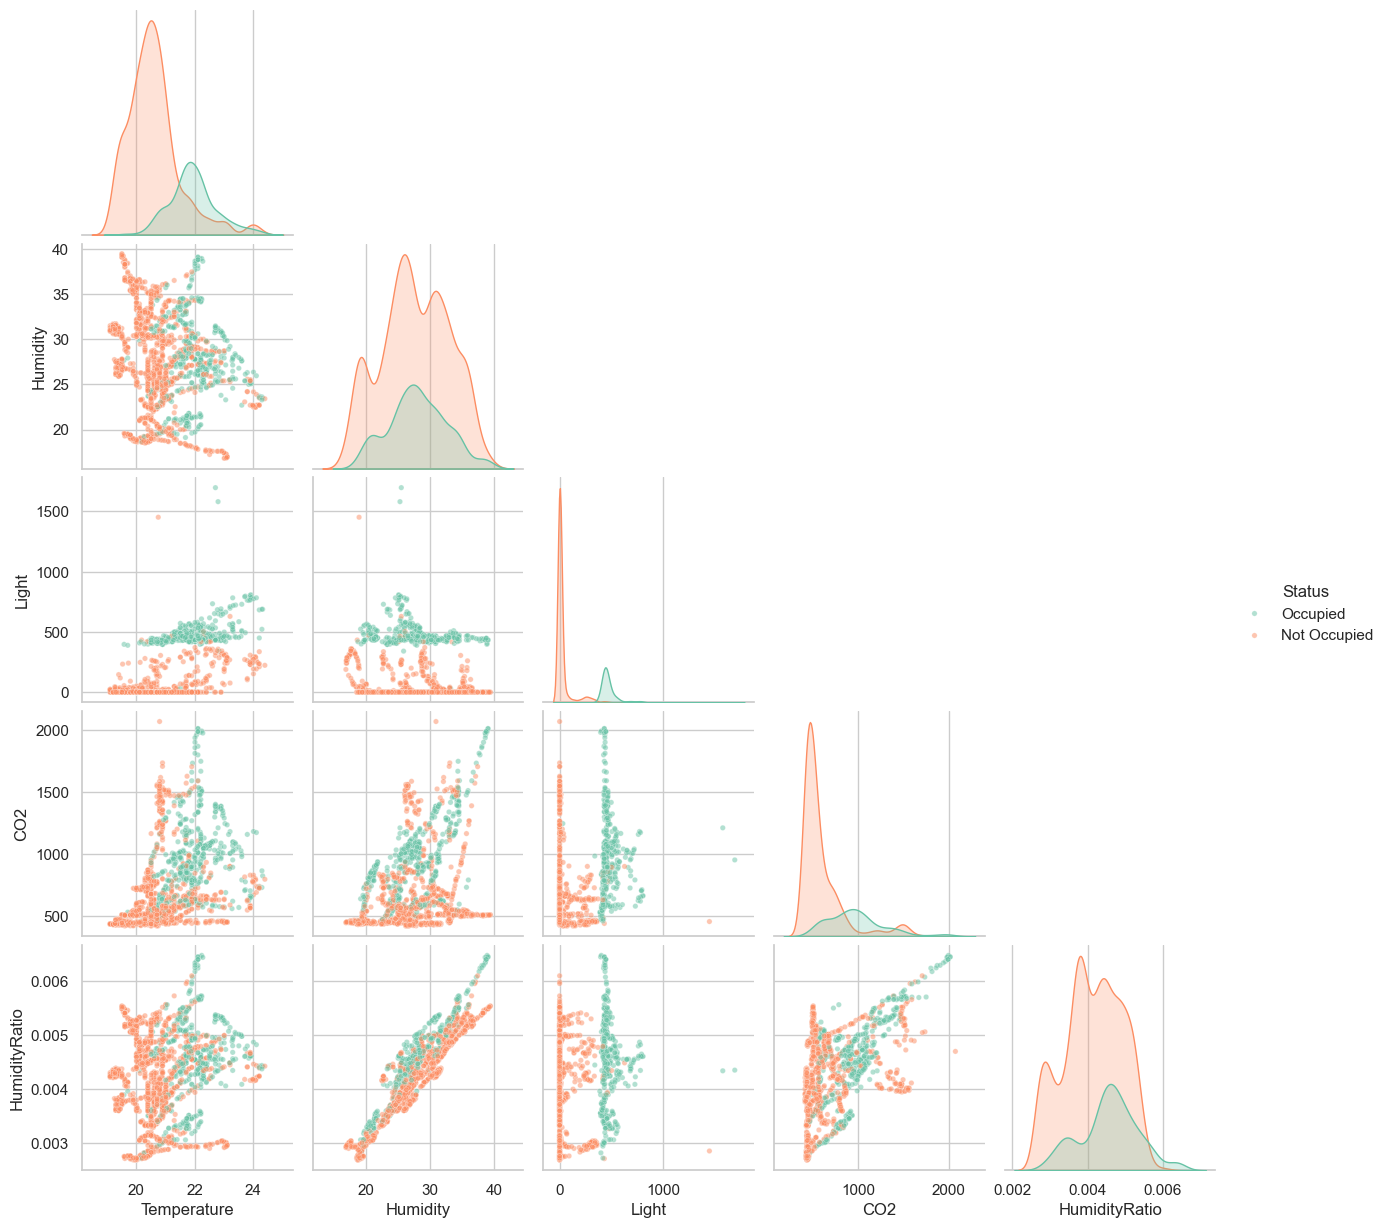

In [19]:
sample = df.sample(min(2000, len(df)), random_state=42)
sns.pairplot(sample, vars=features, hue="Status", palette="Set2",
             plot_kws={"alpha": 0.5, "s": 15}, corner=True)
plt.show()